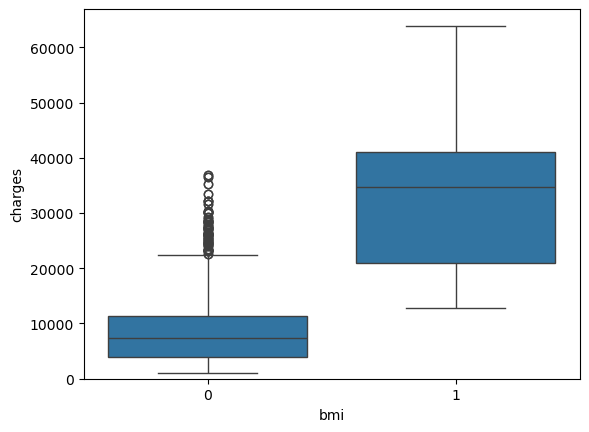

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/medical_insurance_dataset.csv'
df = pd.read_csv(path, header=None)
headers = ["age", "gender", "bmi", "no_of_children", "smoker", "region", "charges"]
df.columns = headers
df.replace('?', np.nan, inplace = True)
age_mean = df['age'].astype('float').mean(axis=0)
df["age"] = df["age"].replace(np.nan, age_mean)
smoker_mfe = df['smoker'].value_counts().idxmax()
df["smoker"] = df["smoker"].replace(np.nan, smoker_mfe)
df[["age","smoker"]] = df[["age","smoker"]].astype("int")
df[["charges"]] = np.round(df[["charges"]],2)
sns.regplot(x="bmi", y="charges", data=df, line_kws={"color": "red"})
plt.ylim(0,)
sns.boxplot(x="smoker", y="charges", data=df)

from sklearn.linear_model import LinearRegression, Ridge
X = df[['smoker']]
Y = df['charges']
lm = LinearRegression()
lm.fit(X,Y)
Z = df[["age", "gender", "bmi", "no_of_children", "smoker", "region"]]
lm.fit(Z,Y)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
Input=[('scale',StandardScaler()), ('polynomial', PolynomialFeatures(include_bias=False)), ('model', LinearRegression())]
pipe=Pipeline(Input)
Z = Z.astype(float)
pipe.fit(Z,Y)
#ypipe=pipe.predict(Z)
from sklearn.model_selection import cross_val_score, train_test_split
x_train, x_test, y_train, y_test = train_test_split(Z, Y, test_size=0.2, random_state=1)
RidgeModel=Ridge(alpha=0.1)
RidgeModel.fit(x_train, y_train)
yhat = RidgeModel.predict(x_test)
pr = PolynomialFeatures(degree=2)
x_train_pr = pr.fit_transform(x_train)
x_test_pr = pr.fit_transform(x_test)
RidgeModel.fit(x_train_pr, y_train)
y_hat = RidgeModel.predict(x_test_pr)
df.to_csv('output.csv', index=False)